<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 4: Human Rights approach to data y privacidad <h2><center>


# Human Rights approach to data y privacidad

>Contexto

En estos talleres, estamos trabajando con datos que pueden influir en vidas de personas. Esto implica una responsabilidad ética especial, las personas o grupos de personas detrás pueden verse impactadas tanto de forma positiva como negativa con las decisiones basadas en datos que tomemos. Antes de hacer cualquier análisis, debes preguntarte cómo tratarías esos datos si fueras quien los recolecta, y cómo podrías compartirlos si resguardar la identidad de los involucrados fuese prioridad.

>Objetivos

El objetivo de este taller es diseñar un marco de recolección de datos basado en derechos humanos sobre los problemas que han estado tratando, así como identificar si cumplen o no con el marco regulatorio chileno, aplicar DataSynthesizer para generar una versión sintética del dataset, generar visualizaciones y proponer mejoras al dataset desde la perspectiva del activismo de datos.

> # instrucciones generales

Esta es la parte IV del proyecto, consideren utilizar sus resultados anteriores y reciclar el código de los talleres previos. El taller puede aplicarse sobre cualquiera de los tres datasets del proyecto; trabajen con el mismo dataset que eligieron en los talleres anteriores y respondan cada pregunta en función de ese contexto.

Si trabajan con CIRI, notarán que sus datos son indicadores agregados por país y año, por lo que no contienen información personal que deba protegerse. Aun así, la idea es que aprendan a utilizar las herramientas de privacidad diferencial y generación de datos sintéticos, ya que el procedimiento es el mismo independiente del dataset, y que reflexionen sobre qué ocurriría si estos datos tuvieran un mayor nivel de detalle, por ejemplo, registros individuales de víctimas, como se plantea en la pregunta 6.

## `Temas formales`

Modalidad: Grupos de 3 personas.

Fecha de entrega: 20 de noviembre.

Formato de entrega: El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

Formalidades de las respuestas:
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "sí" o "no", consideren argumentar sus respuestas y justificar con bibliografía si lo estiman necesario.

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes :D.



In [14]:
import pandas as pd


### _`Importantes: A lo largo del notebook habrán preguntas guías para los análisis de resultados, operación de código y otros, se espera que las respondan o hagan alusión a ellas en sus respuestas `_

<br><br>
**`Pregunta (1`) Describa el objetivo y las variables del dataset desde una perspectiva distinta**.


Nosotros proponemos leer los datos de CASEN como una herramienta de visibilidad, podemos ver quien y cómo es contado, también se puede ver quienes no aparecen o están mal clasificados y son ellos quienes son excluidos de la discusión pública y presupuesto estatal. Viendo de esta manera el dataset, se puede usar como una especie de rendición de cuentas a las personas dede el estado, cada persona deja de ser un caso y es vista como titular de sus datos con derechos de como se utilizan.

¿A simple vista, consideras que alguna de estas variables podría ser mal utilizada, perjudicando a alguna comunidad? 


Si, creemos que algunas de estas variables podrian ser mal utilizadas como por ejemplo r3, r5b que revelan origen étnico de las personas, esta variable puede malutilizarse estigmatizando y atribuyendo por ejemplo la pobreza a las diferentes culturas existentes y no a la desigualdad estructural. Otro ejemplo podría ser utilizar los ingresos y composición del hogar para cosas como exclusión de créditos o arriendos, lo anterior si es que se cruza con la región o comuna puede llevar a una estigmatización territorial.


¿Por qué crees que se consideran esas variables y no otras para el objetivo del dataset?


Creemos que se consideran estas variables y no otras ya que son estas las que responden a la definición de pobreza multidimensional, las cuales son educación, salud, trabajo y seguridad social, vivienda y entorno, redes y cohesión social. Además lo que se mide y la manera de hacerlo es posible hacerlo mediante encuentas y es posible comparar y contrastar a través del tiempo. 

<br><br>



### `2: Exploración de datos y limpieza.`

Basta con que lo hayan realizado en los talleres anteriores, solo consideren usar el dataset limpio para lo que viene.


In [15]:
datos_casen = pd.read_csv("casen_2024.csv")
datos_casen.head()

,area,p1,p2,p3,p4,p9,tot_per_h,edad,sexo,ind_hacina,...,v22,v23,v24,v24b,v27a,v27b,v29b,os1,trans,pobreza_multi
0,Urbano,Casa acceso directo,3,3,3,2,2,62,Hombre,1,...,Llave dentro vivienda,1,Red pública medidor propio,40000.0,1.0,1.0,1.0,Heterosexual,No,No pobre
1,Urbano,Casa acceso directo,3,3,3,2,2,92,Mujer,1,...,Llave dentro vivienda,1,Red pública medidor propio,40000.0,1.0,1.0,1.0,Heterosexual,No,No pobre
2,Urbano,Casa acceso directo,3,3,4,4,4,61,Hombre,1,...,Llave dentro vivienda,1,Red pública medidor propio,28000.0,3.0,1.0,1.0,Heterosexual,No,No pobre
3,Urbano,Casa acceso directo,3,3,4,4,4,61,Mujer,1,...,Llave dentro vivienda,1,Red pública medidor propio,28000.0,3.0,1.0,1.0,Heterosexual,No,No pobre
4,Urbano,Casa acceso directo,3,3,4,4,4,32,Hombre,1,...,Llave dentro vivienda,1,Red pública medidor propio,28000.0,3.0,1.0,1.0,Heterosexual,No,No pobre


### `3: Análisis de principios.`

**`Pregunta (3)` Identifique si el dataset seleccionado cumple con los principios de Human Rights approach to data. Si cumple, explique por qué cumple. Si no cumple, proponga un nuevo marco de recolección o tratamiento que sí cumpla.**

Recuerda apoyarte en bibliografía externa, puedes sugerir marcos y métodos de tratamiento de datos utilizados en casos similares. Argumenta sólidamente tu elección.


Usando los 6 principios del enfoque de derechos humanos en datos del alto comisionado de la ONU.(OHCHR, 2018):

1) Participación: cumple parcialmente ya que se encuentran consultas técnicas como CEPAL, pero no una participación activa y vinculante de las comunidades al momento de planear el cuestionario y sus preguntas.

2) Desagregación: cumple casi completamente ya que se puede desagregar por edad, sexo, pueblo indigena, deiscapacidades y territorio, sin embargo la muestra presenta una estructura que está diseñada para representatividad regional, por lo que los subgrupos mas pequeños como por ejemplo mujeres indigenas tienen un error alto según lo visto en el taller 1

3) Autoidentificación: se cumple de manera parcial ya que r3 se basa en autoidentificación, pero las otras categorias como genero u orientación están acotadas y en las categorias de discapacidad solo hay preguntas funcionales cerradas

4) Transparencia: si cumple ya que la metódologia, libro de códigos y ciertos datos son totalmente públicos y accesibles.

5) Privacidad: cumple de manera parcial ya que los datos públicos son anonimizados, pero no hay garantias formales, teniendo tantas variables existe un riesgo real de reidentificación por cominación.

6) Rendición de cuentas: cumple de manera parcial ya que la institución es identificable, pero las personas encuestadas no pueden conocer los usos que se les dan a sus datos luego de la encuesta.

Con lo anterior proponemos un nuevo marco de tratamiento con las siguentes medidas:

1) que existan instancias donde diferentes organizaciones o comunidades de personas pertenecientes a pueblos indigenas, diversidad sexual, discapacitados puedan válidar o ayudar a diseñar el cuestionario.

2) microdatos solo para investigadores acreditados y que la versión pública sea con generalización de variables o datos sinteticos.

3) tener un datasheet público, que CASEN registre los usos que se le da a los datos y que exista un canal para que las personas puedan ejercer sus derechos sobre sus datos.


<br><br>
### `4: Análisis regulatorio.`

**`Pregunta (4)` Proponga un método de recolección de este tipo de datos imaginando que fuese requerido para Chile. El método debe cumplir con el marco regulatorio chileno, considerando las políticas que entraron y entrarán en vigencia.**


Al momento de explicar el método propuesto, recuerda hacer alusión a principios, temas y/o artículos específicos de la regulación vigente o de discusiones académicas en torno a esta.

Método propuesto.

1) Los datos se recogen con un consentimiento informado y especifico del uso que se les dará, existe la opción de no responder. por principio de finalidad y proporcionalidad solo se preguntará lo justo y necesario, evitando preguntas muy intimas, si existen deben ser muy justificadas,

2) Se evaluaria el impacto de protección de datos por el tratamiento de los datos sensibles a gran escala, esto con participación de las comunidades afectadas

3) Se separarian los identificadores directos de las respuestas, y que serían guardadas en otra unidad. La información se almacena a nivel regional o superior.

4) Se avisaria la finalidad, plazos de conservación y quienes podrán acceder a los datos en lenguaje claro e incluso lengua indigena si es requerido

5) Se implementa un canal para poder ejercer acceso, rectificación, eliminación o bloqueo de los datos según lo requerido por el titular, con la capacidad de tener instancia de reclamos.

6) Tener cifrrado y control de acceso basado en roles, tener un registro de quienes acceden, esto según los principios de seguridad, responsabilidad y confidencialidad.

7) Los microdatos reales solo se públican en entornos protegidos y la versión pública debe pasar por un control de divulgación estadistica y privacidad diferencial. Los datos anonimizados dxe forma irreversible quedan fuera de la ley, por lo que la anonimización se debe evaluar con test.(Rocher et al., 2019)

8) Se debe tener un registro público de usos y modelos que use CASEN.



<br><br>
### `5: Privacidad diferencial.`

**`Pregunta (5)` Aplica las técnicas de privacidad diferencial vistas para anonimizar el dataset y comenta los resultados.**

      - Selecciona a lo más 7 variables para aplicar la técnica. Menciónalas y justifica tu elección.
      - Obtenga la descripción del dataset en alguno de los modos, justifique su elección. Guarde dicha descripción en un archivo local
      (en formato JSON)
      - Genere los datos sintéticos usando DataGenerator
      - Aplique ModelInspector para comparar las distribuciones entre los datos originales y los datos sintéticos.

<br><br>

##### Respuesta 5

Seleccionamos 7 variables, osea las siguientes: `area`, `sexo`, `edad`, `r3` (pertenencia a pueblo indígena), `s13` (sistema previsional de salud), `e1` (alfabetismo) y `pobreza_multi`. Las elegimos ya que, para empezar, estos cubren ejes de desagregación muy importantes con enfoque de los DDHH (justaente sexo, edad, territorio, pueblo indígena). Por otro lado, consideramios que incluyen pilares de suma importancia de pobreza (serían salud, educación). Finalmente porque son las que usamos en los talleres anteriores, asi nos ahorramos algo de tiempo al escoger, y nos sirve para contrastar la pobreza entre los grupos que habíamos visto. Además, son variables cuyo "cruce" genera riesgo de reidentificación, por lo que son las que más nos conviene proteger/"censurar".

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from DataSynthesizer.DataDescriber import DataDescriber
from DataSynthesizer.DataGenerator import DataGenerator
from DataSynthesizer.ModelInspector import ModelInspector
from DataSynthesizer.lib.utils import read_json_file

variables = ["area", "sexo", "edad", "r3", "s13", "e1", "pobreza_multi"]
df = pd.read_csv("casen_2024.csv")
df_og = df[variables]
df_og.to_csv("casen_7vars.csv", index=False)

epsilon, k = 1.0, 2
categoricas = {v: True for v in variables}
categoricas["edad"] = False

el_discraibe = DataDescriber(category_threshold=20)
el_discraibe.describe_dataset_in_correlated_attribute_mode(dataset_file="casen_7vars.csv", epsilon=epsilon, k=k, attribute_to_is_categorical=categoricas, seed=0,)
el_discraibe.save_dataset_description_to_file("descripcion_casen.json")

generador = DataGenerator()
generador.generate_dataset_in_correlated_attribute_mode(len(df_og), "descripcion_casen.json", seed=0)
generador.save_synthetic_data("casen_sintetico.csv")
df_sintetisado = pd.read_csv("casen_sintetico.csv")
df_sintetisado.head()

================ Constructing Bayesian Network (BN) ================
Adding ROOT pobreza_multi
Adding attribute s13
Adding attribute edad
Adding attribute e1
Adding attribute area
Adding attribute r3
Adding attribute sexo
========================== BN constructed ==========================


,area,sexo,edad,r3,s13,e1,pobreza_multi
0,Urbano,Hombre,79.0,No indígena,Isapre,"Sí, lee y escribe",No pobre
1,Rural,Hombre,20.0,No indígena,Sistema Público FONASA,"Sí, lee y escribe",No pobre
2,Urbano,Mujer,45.0,No indígena,Sistema Público FONASA,"Sí, lee y escribe",No pobre
3,Rural,Hombre,28.0,Indígena,Sistema Público FONASA,"Sí, lee y escribe",No pobre
4,Urbano,Mujer,72.0,No indígena,Sistema Público FONASA,"Sí, lee y escribe",No pobre


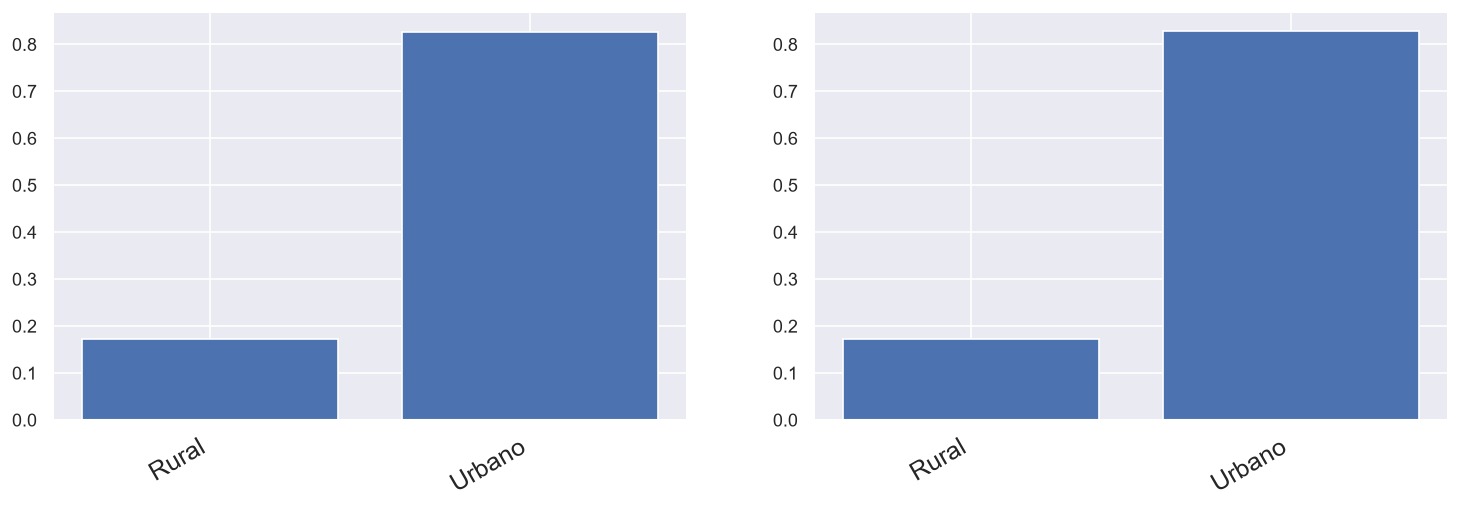

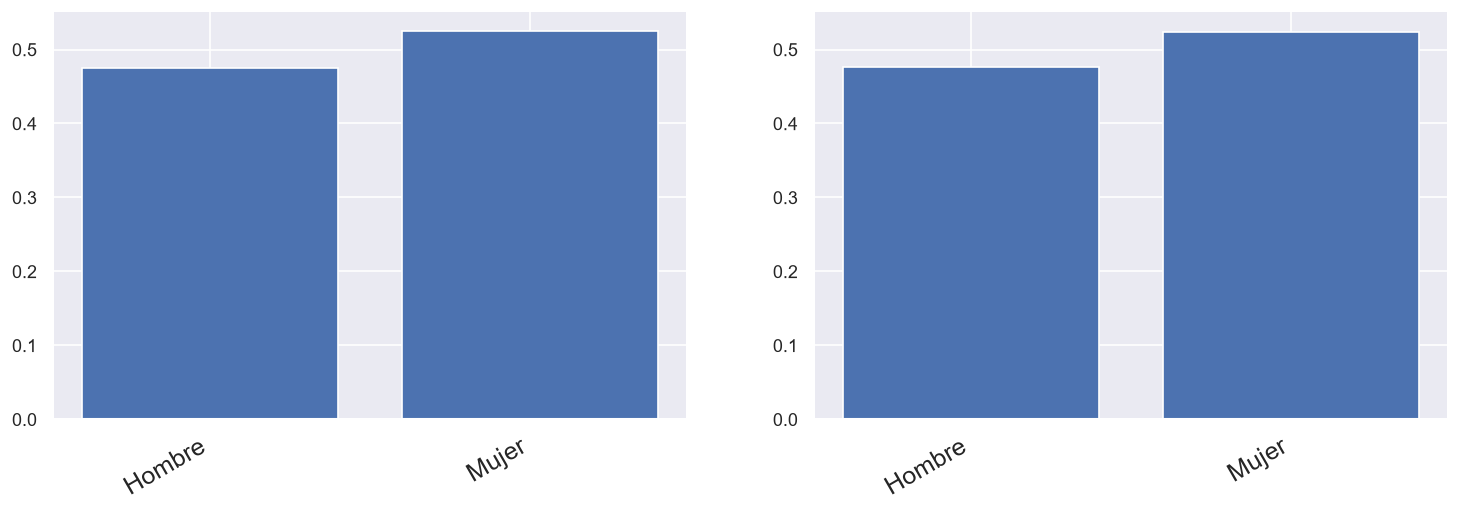

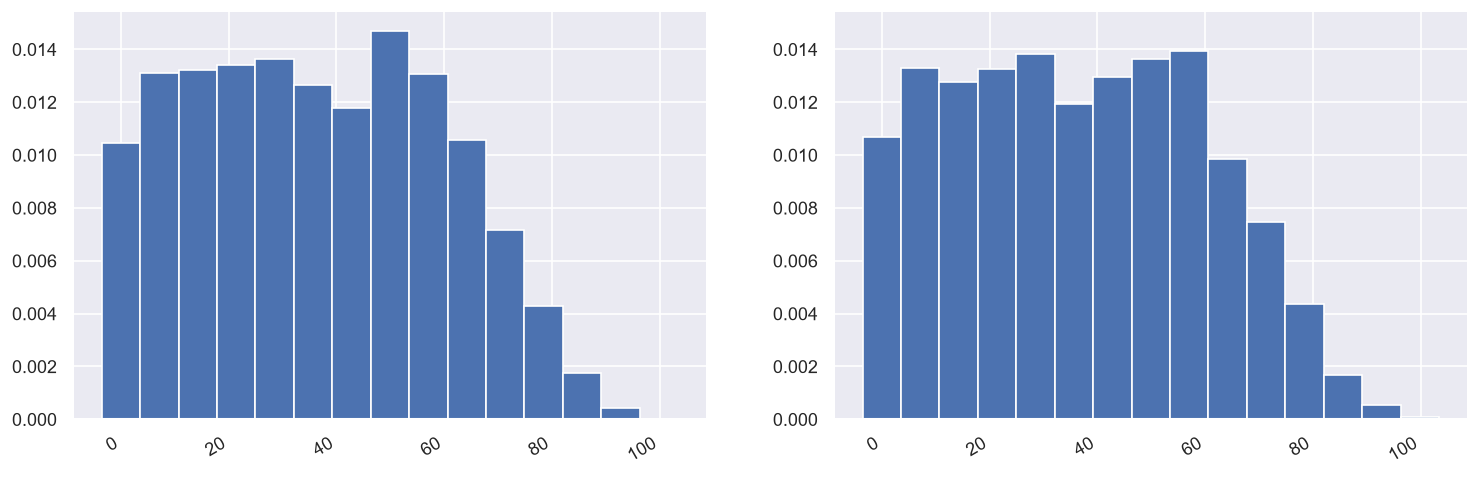

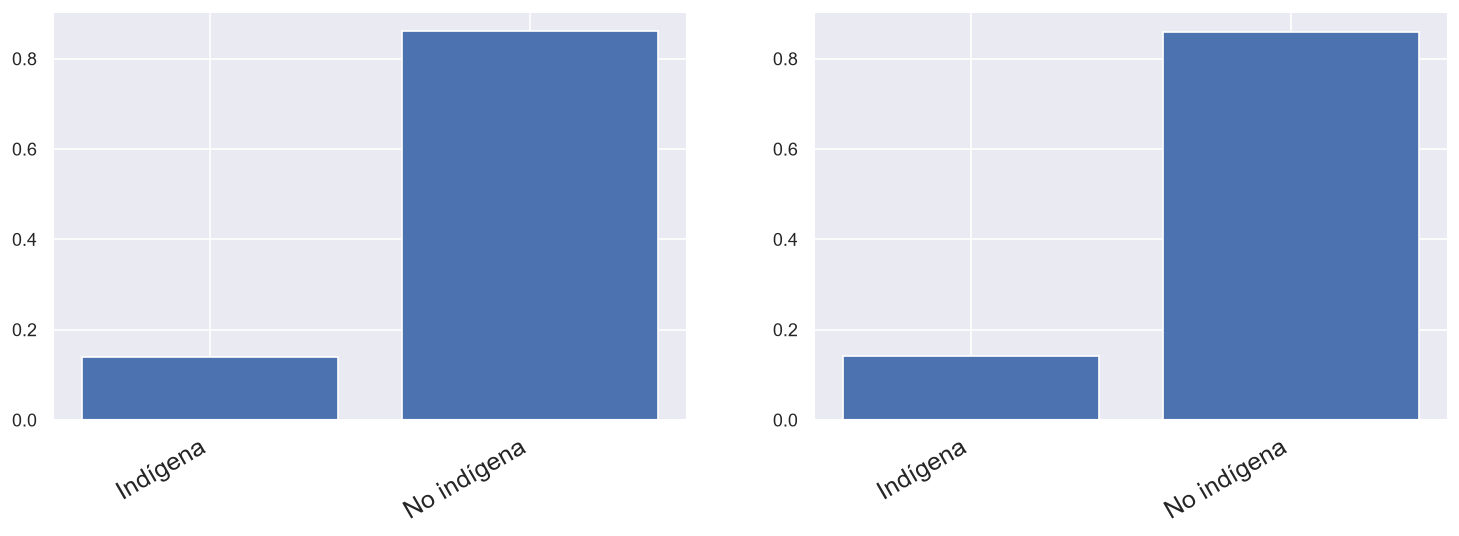

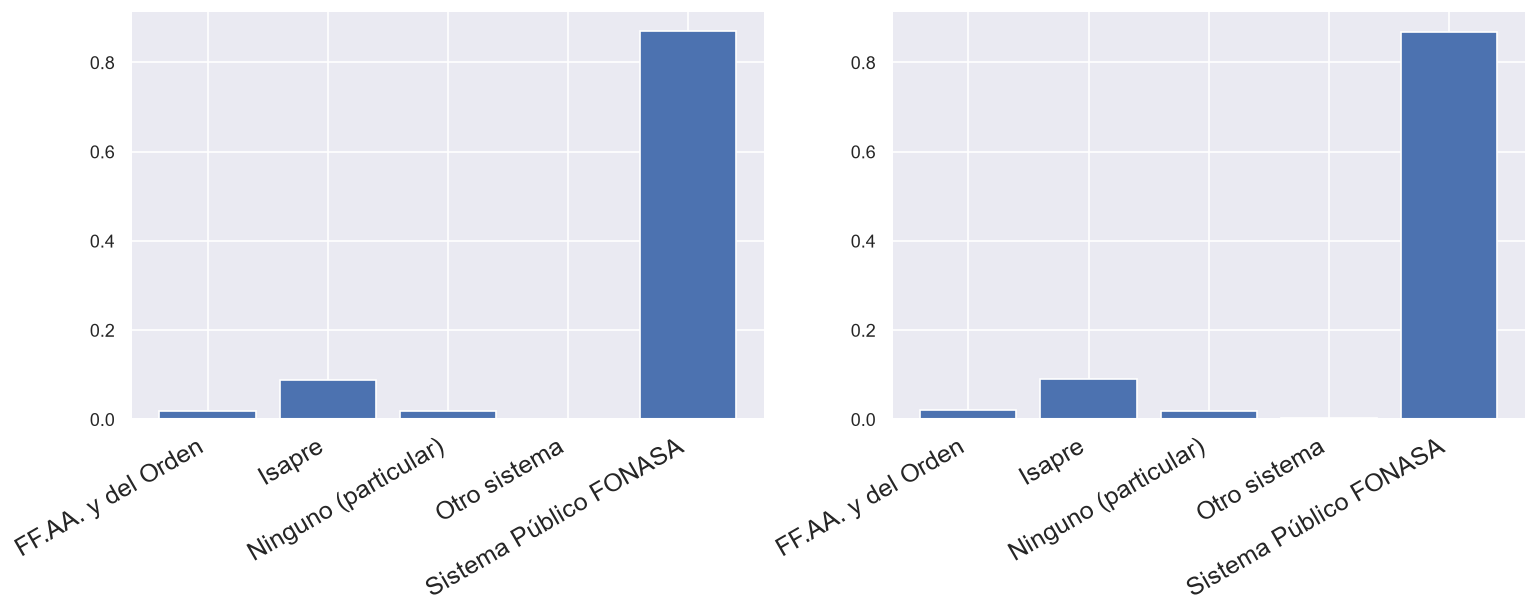

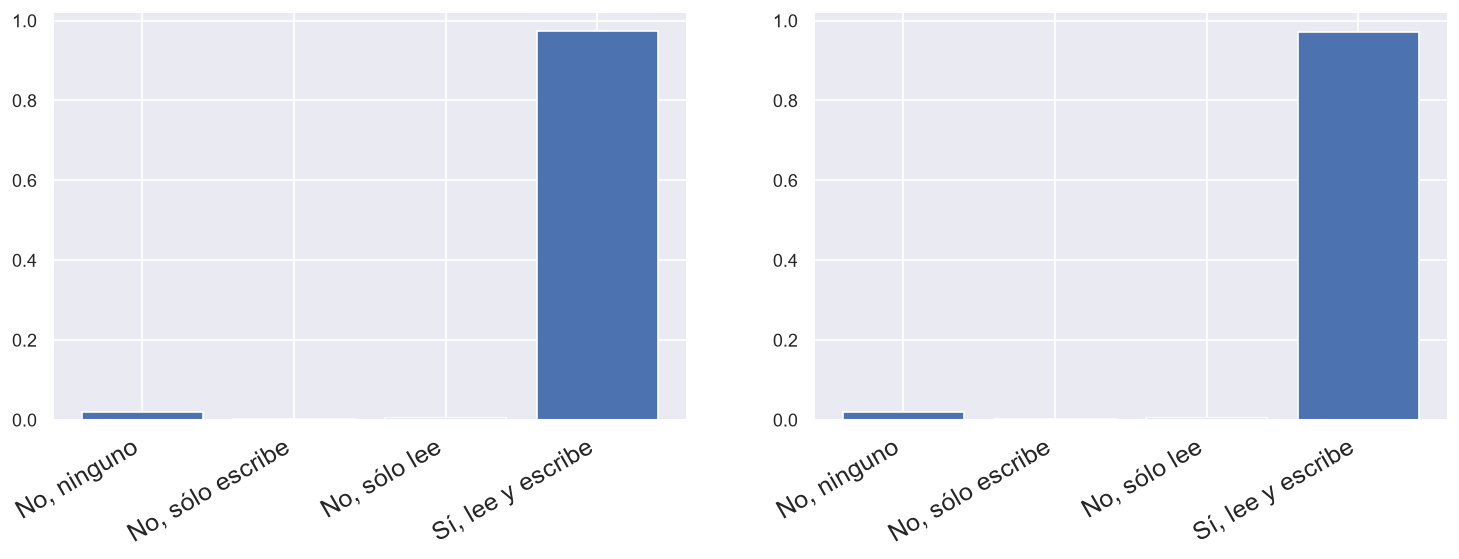

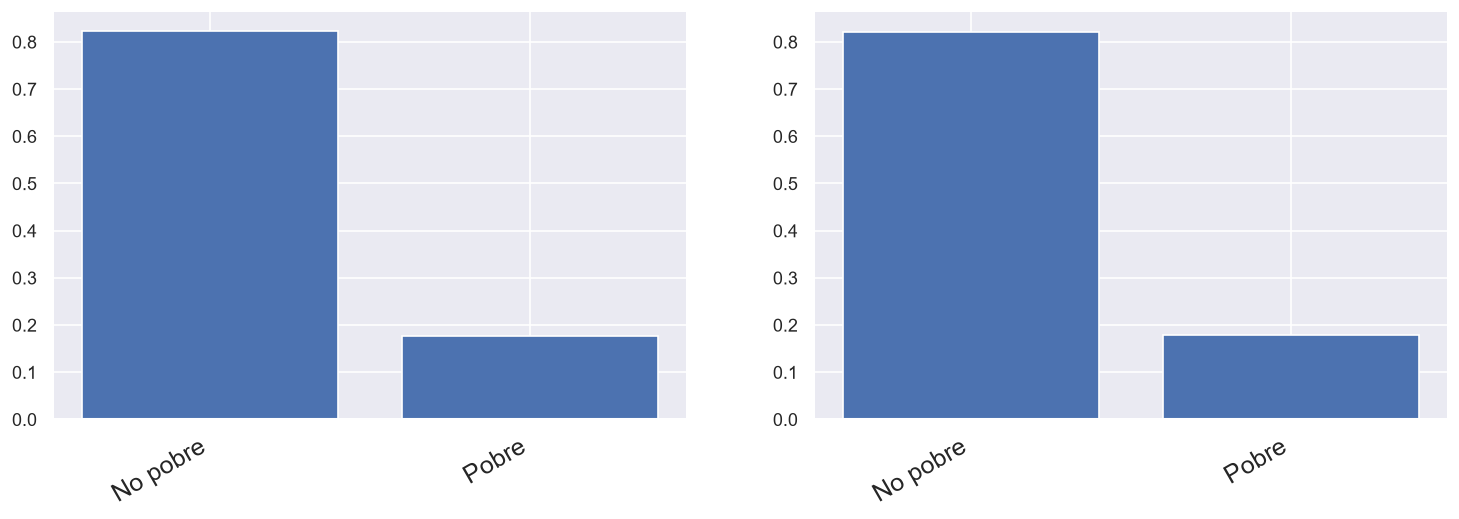

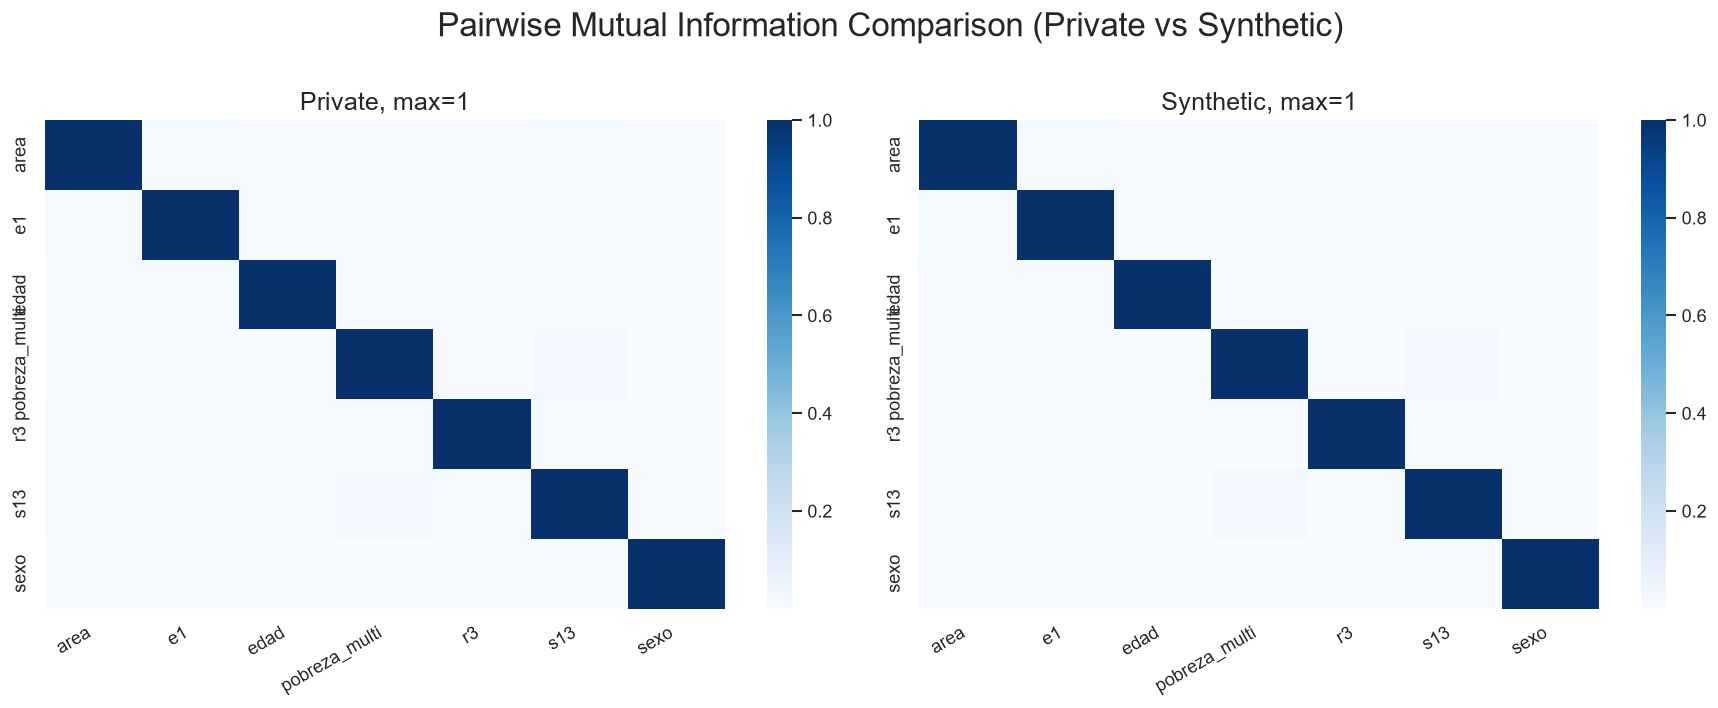

In [17]:
descripcion = read_json_file("descripcion_casen.json")
inspector = ModelInspector(df_og, df_sintetisado, descripcion["attribute_description"])
for v in variables:
    inspector.compare_histograms(v)
    plt.show()
inspector.mutual_information_heatmap(variables)
plt.show()

##### Comentario de resultados 5

Las distribuciones marginales del dataset sintético son basicamente iguales a las del dataset originaal en las siete variables (vean los histogramas). Además, el mapa de información mutua muestra que la estructura de dependencias se mantiene. La información mutua de entre todas las variables es baja en ambos dataets, por lo que no hay asocciacion fuerte alguna que perder a este nivel de agregación.

Imagina que ahora cuentas con este mismo dataset con información mucho más detallada, que podría contribuir a un proyecto desde la Ciencia de Datos con impacto social. Dependiendo del dataset que haya escogido su grupo, consideren el siguiente escenario:

- CIRI: el dataset incluye locaciones específicas, familias y detalles de investigación sobre desapariciones y asesinatos, lo que podría contribuir a un proyecto de búsqueda de víctimas.

- Salud: el dataset incluye identificadores de pacientes, centro de salud de atención y comuna de residencia, lo que podría contribuir a un proyecto de detección temprana o de acceso equitativo a tratamientos.

- CASEN: el dataset incluye la ubicación exacta de cada hogar, su composición familiar y el detalle de ingresos y beneficios recibidos, lo que podría contribuir a focalizar mejor la entrega de ayudas sociales.

En este caso podríamos preguntarnos, ¿qué sería lo correcto? ¿anonimizar o mantener pública toda la información?

**`Pregunta (6)` Proceso de toma de decisiones: Frente a este dilema concreto ¿incluir todos los datos por precisión y transparencia o aplicar técnicas de privacidad para proteger a las personas y sus familias? ¿cómo lo resolverías? cuales son los pros y los contras de esta decisión, en que tipo de contextos compartirías los datos reales y en cuales los datos sinteticos.**


#### Respuesta 6

Creemos y consideramos que el dilema está bastante mal planteado si lo reducimos a "todo público" o "todo anonimizado". Nuestra propuesta es un **"acceso por niveles"**, ya que, siguiendo ccon la lógica de los *Five Safes* (proyectos, personas, entornos, datos y resultados seguros): lo que se publica depende de quién accede, con que objetivo y en donde.

En nuestro caso, CASEN contiene la ubicación exacta del hogar, "composición" familiar e ingresos y beneficios detallados, definitivamente publicar todo es lo peor que se puede hacer, o directamente inaceptable, iría en contra de nuestra intencción. Desarrollando esta idea, sabiendo la ubicación exacta de un hogar, cierta composición (familiar) y cierto ingreso, el conjunto de estos datos es prácticamente único. Como hemos visto en clases y Rocher et al. (2019) muestran que bastan pocos datos o atributoss demográficos para reidentificar a la gran mayoría de las personas, esto incluso con bases de datos incompletas. Además, un dato anonimizado de forma reversible (osea mas bien sería una "anonimación" bien inutil en mi opinión la verdad) sigue siendo dato personal bajo la normativa chilena (Ley N° 19.628, modificada por la Ley N° 21.719), y aquí sabemos que definitivamente tenemos datos sensibles. 

**Pros y contras de cada alternativa**

| | Datos reales completos | Datos protegidos / sintéticos |
|---|---|---|
| A favor | Máxima precisión, permite detectar subgrupos pequeños y focalizar ayudas de forma exacta; mayor transparencia y reproducibilidad | Reduce el riesgo de reidentificación y de daño a hogares vulnerables, es compartible con el público, la academia y organizaciones civiles; cumple mejor el principio de privacidad |
| En contra | Alto riesgo de reidentificación y de estigmatización territorial; los titulares no consintieron ese uso; incumple finalidad y proporcionalidad | Pérdida de precisión (sobre todo en grupos pequeños, como veremos en la Pregunta 7); el sintético no sirve para focalizar a un hogar concreto; requiere elegir $\varepsilon$ y esto es una decisión con costos |

**Usamos IA para hacer esta tabla, ya que no sabemos (no sé) hacerla en markdown

**Cómo lo resolveríamos (lo de acceso por niveles)**

- **Datos reales** (con ubicación exacta, composición familiar e ingresos): Solo acceso dentro del Estado y de entornos seguros para investigadores reconocidos o de confianza (acreditados, que se yo), y requeriran de evaluación de impacto, definir la finalidad, registro de accesos y salida de resultados revisada y revisión cada cierto tiempo de su buen uso. La focalización de ayudas sociales debe ocurrir en este nivel, no con datos públicos.

- **Datos sintéticos o generalizados** (territorio agregado a región o comuna, ingresos por tramos): De acceso facil o libre, en donde incluimos a docencia, exploración inicial, activismo, etc, es decir, aplica a contextos donde el enfoque sea tipo estructura general y no el individuo.

- **Participación**: Las comunidades afectadas (por ejemplo pueblos indígenas) deberían de participar y decidir en la decisión (valga la redundancia) de lo qué se comparte y cómo, otra cosa que podría hacerse es definir representantes o en línea con los principios de participación y rendición de cuentas de OHCHR (2018).


### `6: Activismo de datos.`

**`Pregunta (7)` Reporte los resultados de la técnica de anonimización (ModelInspector) y explique como se podría realizar activismo de datos con el conjunto anonimizado.**



,variable,métrica,valor
0,area,KL,0.00000
1,sexo,KL,0.00001
2,edad,KS,0.00596
3,r3,KL,0.00001
4,s13,KL,0.00007
5,e1,KL,0.00004
6,pobreza_multi,KL,0.00001


,original,sintético,diferencia (pp)
r3: Indígena,0.238,0.194,-4.367
r3: No indígena,0.166,0.175,0.899
area: Rural,0.215,0.196,-1.932
area: Urbano,0.168,0.174,0.608
sexo: Hombre,0.175,0.175,0.021
sexo: Mujer,0.178,0.181,0.300


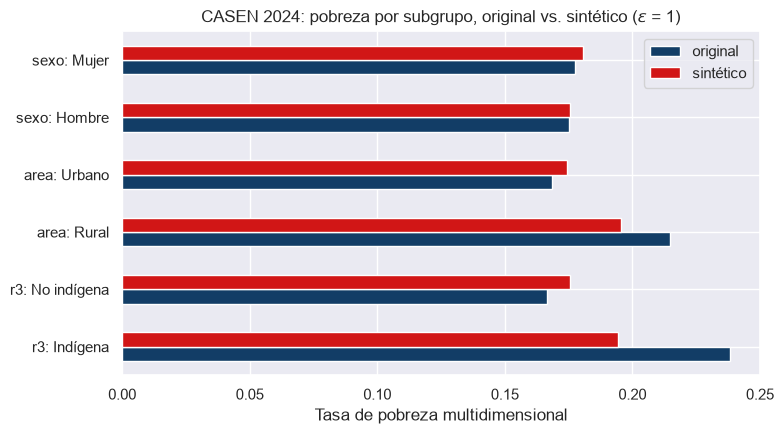

In [19]:
import numpy as np
from scipy.stats import ks_2samp, entropy

filas = []
for v in variables:
    if v == "edad":
        filas.append((v, "KS", ks_2samp(df_og[v], df_sintetisado[v]).statistic))
    else:
        p = df_og[v].value_counts(normalize=True)
        q = df_sintetisado[v].value_counts(normalize=True).reindex(p.index).fillna(1e-9)
        filas.append((v, "KL", float(entropy(p, q))))
metricas = pd.DataFrame(filas, columns=["variable", "métrica", "valor"])
display(metricas.round(5))

def tasa(df, g):
    return df.groupby(g)["pobreza_multi"].apply(lambda s: (s == "Pobre").mean())

comp = []
for g in ["r3", "area", "sexo"]:
    t = pd.concat([tasa(df_og, g), tasa(df_sintetisado, g)], axis=1, keys=["original", "sintético"])
    t.index = [f"{g}: {i}" for i in t.index]
    comp.append(t)
comp = pd.concat(comp)
comp["diferencia (pp)"] = (comp["sintético"] - comp["original"]) * 100
display((comp * 1).round(3))

comp[["original", "sintético"]].plot.barh(figsize=(8, 4.5), color=["#123d66", "#d11616"])
plt.xlabel("Tasa de pobreza multidimensional")
plt.title("CASEN 2024: pobreza por subgrupo, original vs. sintético ($\\varepsilon$ = 1)")
plt.tight_layout()
plt.show()

#### Respuesta 7

**Resultados de ModelInspector.** Las divergencias KL de las variables categóricas son del orden de $10^{-5}$ y el estadístico KS de `edad` es cercano a 0,006. Las proporciones globales de pobreza multidimensional (17,6% vs 17,8%), respecto a pueblos indígenas (14,0% vs 14,1%) y respecto a zonas rurales (17,3% vs 17,2%) casi no cambian (lit solo 0,1%). Pero al mirar subgrupos aparece el verdadero costo de la privacidad, la brecha de pobreza entre personas indígenas y no indígenas pasa de un 23,8% vs 16,6% cuando en el original tenemos un 19,4 % vs 17,5% en el sintético, y la brecha rural-urbana que es en el original 21,5% vs 16,8% a 19,6% vs 17,4% en el sintetico. Es decir, el sintético **subestima** justamente las desigualdades que queremos denunciar. (trabajamos con tasas muestrales no poblacionales btw)

**Cómo hacer activismo de datos con el conjunto anonimizado.**

1. **Abrir la "conversación" sin exponer a nadie**: El sintético puede publicarse junto con el código (es mas, debe), de tal forma que los periodistas, organizaciones y estudiantes repliquen (Si quieren) el análisis, aprendan a usar CASEN y construyan sus propias perspecctivas/visualizaciones sobre quién es contado y quién no, sin riesgo para los hogares encuestados.

2. **Auditar con el enfoque de derechos humanos**: Usar el sintético para mostrar qué grupos tienen mayor pobreza multidimensional o también mayor error muestal. Además exigir desagregación y muestras que permitan ver a los subgrupos pequeños y sus enfoques en el desarrollo.

Por todo esto, usaríamos principalmente el sintético para publicar, comunicar y movilizar con la advertencia explícita de que las brechas reales son mayores, y los datos reales son solo para el análisis profundo en entornos seguros y de confianza que no se "malusen".

Bibliografía

Office of the United Nations High Commissioner for Human Rights. (2018). *A human rights-based approach to data: Leaving no one behind in the 2030 Agenda for Sustainable Development*. United Nations.


Rocher, L., Hendrickx, J. M., & de Montjoye, Y.-A. (2019). Estimating the success of re-identifications in incomplete datasets using generative models. *Nature Communications*, *10*, Artículo 3069. https://doi.org/10.1038/s41467-019-10933-3

D'Ignazio, C., & Klein, L. F. (2020). *Data feminism*. MIT Press.

Dwork, C., & Roth, A. (2014). The algorithmic foundations of differential privacy. *Foundations and Trends in Theoretical Computer Science*, *9*(3-4), 211-407. https://doi.org/10.1561/0400000042

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé, H., III, & Crawford, K. (2021). Datasheets for datasets. *Communications of the ACM*, *64*(12), 86-92. https://doi.org/10.1145/3458723

Ping, H., Stoyanovich, J., & Howe, B. (2017). DataSynthesizer: Privacy-preserving synthetic datasets. *Proceedings of the 29th International Conference on Scientific and Statistical Database Management* (Artículo 42). ACM. https://doi.org/10.1145/3085504.3091117
